<div align="center">

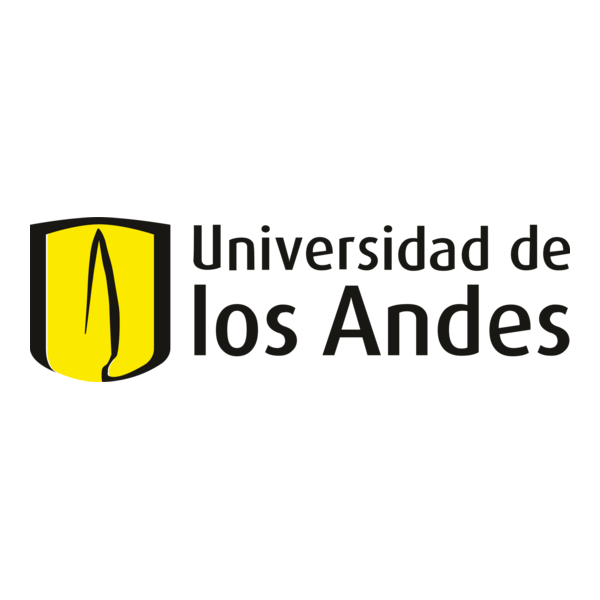

<h1>Proyecto de grado</h1>
<strong>Recuperación semántica y clasificación de la función de citas académicas en Computer Science</strong>
<p>Universidad de los Andes · Maestría en Inteligencia Artificial · Grupo 15</p>
<p>Sebastian Toro · Camilo Bejarano · German Rodriguez · Jose Arteaga</p>
</div>

**Reparto del texto · SciBERT**

Probamos cuánto espacio conviene reservar para el contexto de la cita y cuánto para la información del citado. Conservamos las dos entradas de la propuesta: contexto con título y abstract, y contexto con los tres fragmentos recuperados y sus secciones.

**Alcance de los datos.** Usamos training v2 de G15 y aprovechamos las etiquetas
humanas de T_A que corresponden a filas permitidas de nuestra entrega, según el
[contrato, §§10 y 12](https://drive.google.com/file/d/1X7JXN5ZvoYJodhRxdT5Y-8wOaDlXwRXi/view)
y el [README de A3, §§3 y 4](https://drive.google.com/file/d/1m55jsSkHlb-MlCTJKgy36X4EIK8x23GN/view).
También se aplica a nuestra validación interna. Las reservas nunca anotadas conservan
su etiqueta automática. Nuestro conjunto humano T_B permanece separado del aprendizaje.

## 1. Nuestros datos y sus categorías

Empezamos viendo los ejemplos que realmente usamos: las clases, su distribución y
cuántas etiquetas son automáticas o revisadas por personas. Verificamos los archivos
y la separación por documento antes de dibujar las gráficas.


Mounted at /content/drive


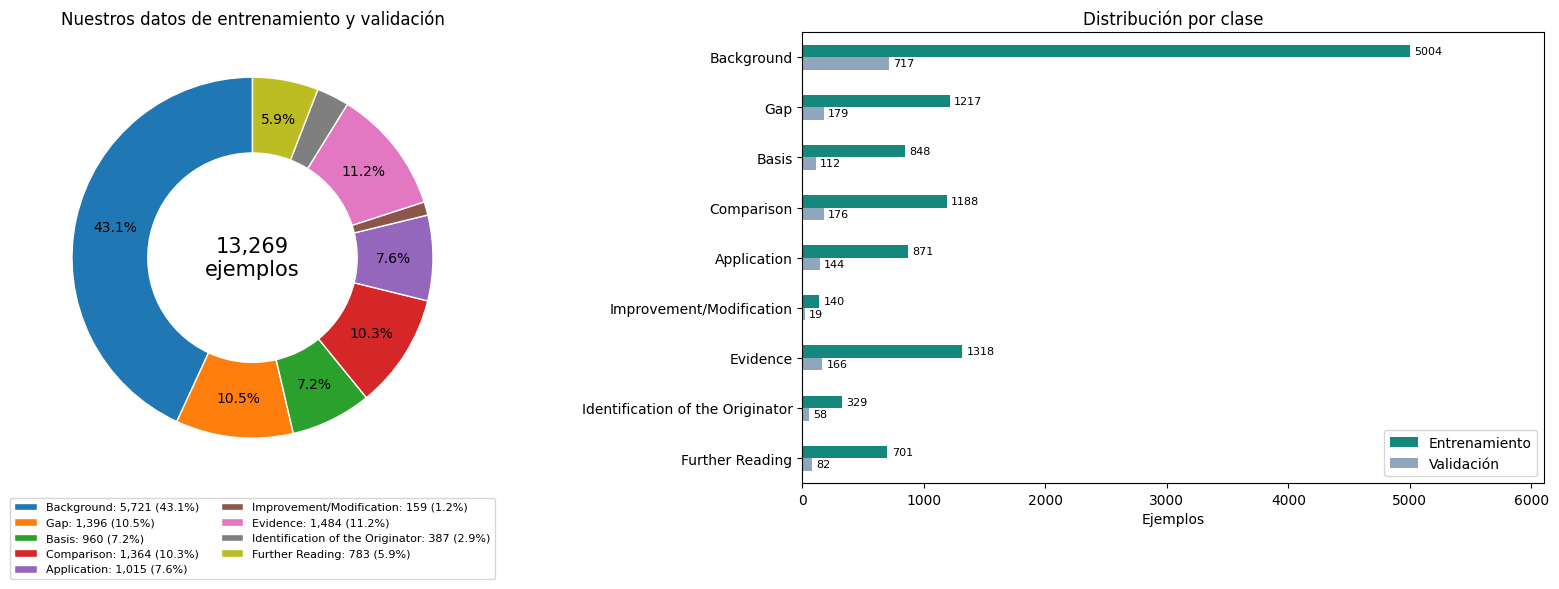

,Entrenamiento,Validación
Background,5004,717
Gap,1217,179
Basis,848,112
Comparison,1188,176
Application,871,144
Improvement/Modification,140,19
Evidence,1318,166
Identification of the Originator,329,58
Further Reading,701,82


,Entrenamiento,Validación
Etiqueta automática,10672,1528
Etiqueta humana,944,125


Usamos 11,616 ejemplos para entrenar y 1,653 para validar.
La clase más frecuente es Background (43.1%); la menos frecuente es Improvement/Modification (159 ejemplos).


In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import sys
import subprocess
import importlib.metadata
from pathlib import Path
import torch

# Comprobación técnica previa a cualquier preparación o entrenamiento.
if not torch.cuda.is_available() or "A100" not in torch.cuda.get_device_name(0) or not torch.cuda.is_bf16_supported():
    raise RuntimeError("La aceleración requerida no está disponible en el intérprete seleccionado.")
PINNED = ["transformers==4.57.1","accelerate==1.11.0","datasets==4.3.0",
    "scikit-learn==1.7.2","matplotlib==3.10.7","safetensors==0.6.2","mlflow==3.17.2"]
installation = subprocess.run([sys.executable,"-m","pip","install","-q",*PINNED],capture_output=True,text=True)
if installation.returncode:
    raise RuntimeError("No se pudieron preparar las bibliotecas: " + installation.stdout[-1500:] + installation.stderr[-1500:])
for requirement in PINNED:
    package,expected = requirement.split("==")
    module = "sklearn" if package=="scikit-learn" else package
    loaded = sys.modules.get(module)
    if loaded is not None and getattr(loaded,"__version__",expected)!=expected:
        raise RuntimeError("Reinicia el intérprete para utilizar las versiones que acabamos de preparar.")

DATA_ROOT = Path(os.environ.get("SCIBERT_DATA_ROOT","/content/drive/MyDrive/MAIA_PROYECTO"))
RESULTS_ROOT = Path(os.environ.get("SCIBERT_RESULTS_ROOT","/content/drive/MyDrive/MAIA_TESIS"))
if not DATA_ROOT.is_dir() or not RESULTS_ROOT.is_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError as error:
        raise RuntimeError("Configura SCIBERT_DATA_ROOT y SCIBERT_RESULTS_ROOT con las carpetas accesibles.") from error
if not DATA_ROOT.is_dir() or not RESULTS_ROOT.is_dir():
    raise FileNotFoundError("Revisa las carpetas de entradas y resultados.")
if RESULTS_ROOT.resolve().is_relative_to(DATA_ROOT.resolve()):
    raise ValueError("La carpeta de resultados debe estar fuera de los datos compartidos.")

RUN_ID = "g15_scibert_reparto_v2_01"
STUDY_KIND = "reparto"
OUTPUT_ROOT = RESULTS_ROOT/"a4"/RUN_ID
TRACKING_ROOT = Path("/opt/maia/a4_tracking_experiments")/RUN_ID
SNAPSHOTS_ROOT = OUTPUT_ROOT/"_tracking/snapshots"
IDS_DIR = RESULTS_ROOT/"TrainingData_Grupo15_v2"
OLD_IDS_DIR = RESULTS_ROOT/"TrainingData_Grupo15"
A3_DIR = DATA_ROOT/"a3"
BATCH_DIR = DATA_ROOT/"a2/batches_norw"
TRAINING_MANIFEST_SHA256 = "c7dd23f92b2272338a9d98dec7cf86476937658aa09a8cd3706c9402be34e231"
A3_MANIFEST_SHA256 = "30118fea362fc4c0389ab34e2460d566d886d5dd7f11e8a84483b62b98a7ce5b"
MODEL_ID = "allenai/scibert_scivocab_uncased"
MODEL_REVISION = "24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1"
CONFIGS = ["base","fragmentos"]
SEED = 42
MAX_LENGTH = 512
CONTEXT_BUDGET = 192
TRAIN_BATCH = 16
GRAD_ACCUM = 2
EVAL_BATCH = 32
USE_BF16 = True
LABELS = ["Background","Gap","Basis","Comparison","Application","Improvement/Modification",
    "Evidence","Identification of the Originator","Further Reading"]
LABEL2ID = {label:i for i,label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
import collections
import gc
import hashlib
import itertools
import json
import math
import shutil
import time
import uuid
import numpy as np
import pandas as pd
from IPython.display import display,Markdown

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".partial_" + uuid.uuid4().hex)
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False, default=str) + "\n", encoding="utf-8")
    os.replace(temp, path)

def freeze_json(path, value):
    path = Path(path)
    if path.exists() and json.loads(path.read_text(encoding="utf-8")) != value:
        raise ValueError(f"La configuración guardada es distinta: {path.name}. Usa otro RUN_ID.")
    save_json(path, value)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def tree_hashes(directory):
    directory = Path(directory)
    return {p.relative_to(directory).as_posix(): sha256(p) for p in sorted(directory.rglob("*")) if p.is_file()}

def verify_files(directory, hashes):
    directory = Path(directory).resolve()
    if not hashes:
        raise ValueError("El cierre no contiene archivos verificables.")
    for name, expected in hashes.items():
        path = (directory / name).resolve()
        if not path.is_relative_to(directory) or not path.is_file() or sha256(path) != expected:
            raise ValueError(f"Archivo guardado ausente o modificado: {name}")

def prepare_final_data(ids_dir, a3_dir, old_ids_dir, output, labels, training_hash, a3_hash,
                       split_seed="G15-A4-split-v1", validation_fraction=.10):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    manifest, raw, gold, test_ids, hashes, closure = load_a3_release(
        ids_dir, a3_dir, old_ids_dir, labels, training_hash, a3_hash)
    rules = release_rules(read_records(Path(ids_dir) / "exclusion_list_G15_V2_v2.jsonl"))
    eligible = [dict(r) for r in raw if not release_excluded(r, rules)]
    labeled, unclear, corrected = attach_ta_gold(eligible, gold, labels)

    def validation_citing(citing):
        digest = hashlib.sha256(f"{split_seed}|val|{citing}".encode()).hexdigest()
        return int(digest[:16], 16) / 2**64 < validation_fraction

    validation = [r for r in labeled if validation_citing(r["citing_paper_id"])]
    candidates = [r for r in labeled if not validation_citing(r["citing_paper_id"])]
    val_docs = document_set(validation)
    train = [r for r in candidates if not {r["citing_paper_id"], r["cited_paper_id"]} & val_docs]
    audit_release_splits(train, validation, test_ids)
    splits = {"train": train, "validation": validation}
    counts = pd.DataFrame({k: collections.Counter(r["label"] for r in rows) for k, rows in splits.items()}).reindex(labels).fillna(0).astype(int)
    if counts.eq(0).any().any():
        raise ValueError("Cada clase debe estar representada en entrenamiento y validación.")
    if any(r.get("gold_set") == "B" or r.get("test_set") == "B" and r.get("sample_status") == "active"
           for rows in splits.values() for r in rows):
        raise ValueError("Una cita de la prueba propia intentó entrar al aprendizaje.")
    fields = ["inst_key", "group_key", "citing_paper_id", "cited_paper_id", "label", "label_source", "source_batch"]
    split_hashes = {}
    for name, rows in splits.items():
        rows.sort(key=lambda r: r["inst_key"])
        content = "".join(json.dumps({k: r[k] for k in fields}, ensure_ascii=False, sort_keys=True) + "\n" for r in rows)
        split_hashes[name] = hashlib.sha256(content.encode()).hexdigest()
        path = output / f"split_{name}_ids.jsonl"
        if path.exists() and path.read_text(encoding="utf-8") != content:
            raise ValueError("Las particiones cambiaron. Usa otro RUN_ID.")
        path.write_text(content, encoding="utf-8")
    source_counts = pd.DataFrame({k: collections.Counter(r["label_source"] for r in rows) for k, rows in splits.items()}).fillna(0).astype(int)
    counts.to_csv(output / "split_class_counts.csv")
    source_counts.to_csv(output / "split_label_sources.csv")
    summary = {"dataset_release": "training_v2", "isolation": "V2", "raw_rows": len(raw),
        "rows_after_exclusions": len(eligible), "removed_unclear": len(unclear),
        "corrected_prelabels": corrected, "removed_for_validation_isolation": len(candidates)-len(train),
        "rows": {k: len(v) for k, v in splits.items()}, "split_hashes": split_hashes,
        "input_hashes": hashes, "label_sources": source_counts.to_dict(),
        "split_seed": split_seed, "validation_fraction_target": validation_fraction,
        "temporal_split": False, "section_stratification": False, "test_scored": False,
        "contract_url": "https://drive.google.com/file/d/1X7JXN5ZvoYJodhRxdT5Y-8wOaDlXwRXi/view",
        "release_readme_url": "https://drive.google.com/file/d/1m55jsSkHlb-MlCTJKgy36X4EIK8x23GN/view"}
    freeze_json(output / "data_manifest.json", summary)
    save_json(output / "label_provenance.json", {"human_source_set": "A", "own_test_set": "B",
        "rule": "join by inst_key; replace eligible prelabels with final gold; never append own test",
        "source_counts": source_counts.to_dict(), "corrected_prelabels": corrected,
        "removed_unclear_keys": unclear})
    save_json(output / "a3_closure.json", closure)
    return splits, test_ids, hashes, split_hashes, counts, source_counts, summary

def show_final_data(counts, source_counts, output):
    import matplotlib.pyplot as plt
    totals = counts.sum(axis=1)
    fig, (pie, bars) = plt.subplots(1, 2, figsize=(17, 6))
    wedges, _, _ = pie.pie(totals, startangle=90, autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
        pctdistance=.78, colors=plt.get_cmap("tab10")(np.arange(len(totals))),
        wedgeprops={"width": .42, "edgecolor": "white"})
    pie.text(0, 0, f"{int(totals.sum()):,}\nejemplos", ha="center", va="center", fontsize=15)
    pie.set_title("Nuestros datos de entrenamiento y validación")
    pie.legend(wedges, [f"{k}: {v:,} ({v/totals.sum():.1%})" for k, v in totals.items()],
        loc="upper center", bbox_to_anchor=(.5, -.02), fontsize=8, ncol=2)
    counts.rename(columns={"train":"Entrenamiento", "validation":"Validación"}).plot.barh(ax=bars, color=["#16877c", "#8fa6be"])
    bars.invert_yaxis()
    for container in bars.containers:
        bars.bar_label(container, fmt="%.0f", padding=3, fontsize=8)
    bars.set(xlabel="Ejemplos", ylabel="", title="Distribución por clase")
    bars.set_xlim(0, int(counts.train.max())*1.22)
    fig.tight_layout()
    fig.savefig(Path(output)/"eda_class_distribution.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    display(counts.rename(columns={"train":"Entrenamiento", "validation":"Validación"}))
    display(source_counts.rename(index={"pre_label":"Etiqueta automática", "human_gold":"Etiqueta humana"},
        columns={"train":"Entrenamiento", "validation":"Validación"}))
    print(f"Usamos {int(counts.train.sum()):,} ejemplos para entrenar y {int(counts.validation.sum()):,} para validar.")
    print(f"La clase más frecuente es {totals.idxmax()} ({totals.max()/totals.sum():.1%}); la menos frecuente es {totals.idxmin()} ({int(totals.min()):,} ejemplos).")

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_records(path):
    with Path(path).open(encoding="utf-8-sig") as stream:
        return [json.loads(line) for line in stream if line.strip()]

def keyed_records(rows, name):
    result = {}
    for row in rows:
        key = row["inst_key"]
        if key in result:
            raise ValueError(f"Hay una clave repetida en {name}: {key}")
        citing, para, span, cited = key.split("|")
        if citing != row["citing_paper_id"] or cited != row["cited_paper_id"] or citing == cited:
            raise ValueError(f"La clave no corresponde a sus artículos en {name}: {key}")
        if not row["group_key"].startswith(f"{citing}|{para}|"):
            raise ValueError(f"El grupo de citas no corresponde a la clave en {name}: {key}")
        result[key] = row
    return result

def checked_file(root, name, expected, hashes):
    root = Path(root).resolve()
    path = (root / name).resolve()
    if path.parent != root:
        raise ValueError("El manifiesto contiene una ruta fuera de su carpeta.")
    actual = file_hash(path)
    if actual != expected:
        raise ValueError(f"El archivo cambió respecto de la entrega revisada: {name}")
    hashes[str(path)] = actual
    return path

def load_a3_release(ids_dir, a3_dir, old_ids_dir, labels, training_manifest_hash, metrics_manifest_hash):
    ids_dir, a3_dir, old_ids_dir = map(Path, [ids_dir, a3_dir, old_ids_dir])
    hashes = {}
    manifest_path = checked_file(ids_dir, "manifest_training_v2_G15.json", training_manifest_hash, hashes)
    metrics_path = checked_file(a3_dir, "manifest_metrics.json", metrics_manifest_hash, hashes)
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    if (manifest["group"], manifest["test_set"], manifest["version"], manifest["variant"]) != ("G15", "B", "v2", "V0"):
        raise ValueError("Esta corrida espera la entrega training v2 de G15, cuyo punto de partida es V0.")
    required = {"training_v2_G15.jsonl", *(f"exclusion_list_G15_{v}_v2.jsonl" for v in ["V0", "V1", "V2"])}
    if not required <= manifest["files"].keys():
        raise ValueError("Faltan archivos de entrenamiento o de exclusión en el manifiesto.")
    for name, digest in manifest["files"].items():
        checked_file(ids_dir, name, digest, hashes)
    gold_path = checked_file(a3_dir, "test_set_gold.jsonl", metrics["files"]["test_set_gold.jsonl"], hashes)
    rows, gold = read_records(ids_dir / "training_v2_G15.jsonl"), read_records(gold_path)
    row_index, gold_index = keyed_records(rows, "training v2"), keyed_records(gold, "gold A3")
    if len(rows) != manifest["v2_rows"] or len(gold) != metrics["packages"]:
        raise ValueError("La cantidad de filas no coincide con los manifiestos.")
    if not all(r["high_confidence"] and r["primary_pre_label"] in labels for r in rows):
        raise ValueError("Hay una fila sin preetiqueta válida de alta confianza.")
    for record in gold:
        if record["set"] not in {"A", "B"} or type(record["in_eval"]) is not bool:
            raise ValueError("Conjunto o marca in_eval inválidos en A3.")
        if record["gold_primary"] not in labels + ["unclear"]:
            raise ValueError("Hay una categoría humana desconocida.")
        if record["in_eval"] != (record["gold_primary"] != "unclear"):
            raise ValueError("La etiqueta humana y su marca de evaluación se contradicen.")
    for group in ["A", "B"]:
        valid = sum(r["set"] == group and r["in_eval"] for r in gold)
        unclear = sum(r["set"] == group and not r["in_eval"] for r in gold)
        if valid != metrics["in_eval"][group] or unclear != metrics["unclear"][group]:
            raise ValueError("El cierre humano no coincide con su manifiesto.")
    own_gold = [g for g in gold if g["set"] == "B"]
    if set(row_index) & {g["inst_key"] for g in own_gold}:
        raise ValueError("Se encontró una cita de T_B dentro del entrenamiento: detener.")
    # Recuperar localizadores, no etiquetas antiguas, para identificar el test de A3.
    old_manifest_path = old_ids_dir / "manifest_training_v1_G15.json"
    old_manifest = json.loads(old_manifest_path.read_text(encoding="utf-8"))
    hashes[str(old_manifest_path)] = file_hash(old_manifest_path)
    for name in ["training_v1_G15.jsonl", "test_set_ids_G15.jsonl"]:
        checked_file(old_ids_dir, name, old_manifest["files"][name], hashes)
    old_rows = read_records(old_ids_dir / "training_v1_G15.jsonl")
    old_index = keyed_records(old_rows, "training v1")
    old_test_index = keyed_records(read_records(old_ids_dir / "test_set_ids_G15.jsonl"), "test IDs v1")
    if not old_index.keys() <= row_index.keys() or len(old_rows) != manifest["v1_rows"]:
        raise ValueError("La entrega v2 no conserva todas las filas de v1.")
    regained = [r for r in rows if r["inst_key"] not in old_index]
    if len(regained) != manifest["rows_regained"] or dict(collections.Counter(r["primary_pre_label"] for r in regained)) != manifest["regained_per_label"]:
        raise ValueError("Las reservas recuperadas no coinciden con el manifiesto.")
    test_ids = []
    for record in own_gold:
        if record["inst_key"] not in old_test_index:
            raise ValueError("Una cita del cierre T_B no está en sus identificadores originales.")
        source = old_test_index[record["inst_key"]]
        test_ids.append({k: source[k] for k in ["inst_key", "group_key", "citing_paper_id", "cited_paper_id", "source_batch"]})
    closure_counts = collections.Counter(r["gold_primary"] for r in own_gold if r["in_eval"])
    expected = {"Background": 330, "Gap": 310, "Basis": 322, "Comparison": 313,
                "Application": 400, "Improvement/Modification": 268, "Evidence": 386,
                "Identification of the Originator": 324, "Further Reading": 315}
    if dict(closure_counts) != expected:
        raise ValueError("Los cupos de T_B difieren del cierre revisado del 9 de noviembre.")
    closure = {"date": "2026-11-09", "valid_test_rows": metrics["in_eval"]["B"],
               "unclear_test_rows": metrics["unclear"]["B"], "valid_test_counts": dict(closure_counts),
               "quota_note": "Cierre sin ola 4: Improvement/Modification tiene 268 casos válidos, según iaa_report.",
               "test_scored": False, "dataset_release": "training_v2", "regained_rows": len(regained)}
    return manifest, rows, gold, test_ids, hashes, closure

def release_rules(rows):
    rules = {"citing": set(), "cited": set()}
    for row in rows:
        if row["group"] != "G15" or row["role"] not in rules:
            raise ValueError("La lista de exclusión no corresponde a G15 o tiene un rol desconocido.")
        rules[row["role"]].add(row["paper_id"])
    return rules

def release_excluded(row, rules):
    return row["citing_paper_id"] in rules["citing"] or row["cited_paper_id"] in rules["cited"]

def attach_ta_gold(rows, gold, labels):
    index = keyed_records(gold, "gold A3")
    labeled, dropped, corrected = [], [], 0
    for row in rows:
        human = index.get(row["inst_key"])
        if human is not None and human["set"] != "A":
            raise ValueError("Solo se permite incorporar etiquetas humanas de T_A al entrenamiento.")
        if human is not None and not human["in_eval"]:
            dropped.append(row["inst_key"])
            continue
        label = human["gold_primary"] if human else row["primary_pre_label"]
        if label not in labels:
            raise ValueError("Hay una etiqueta de entrenamiento desconocida.")
        corrected += bool(human and label != row["primary_pre_label"])
        labeled.append({**row, "label": label, "label_source": "human_gold" if human else "pre_label",
                        "gold_set": "A" if human else None})
    return labeled, dropped, corrected

def document_set(rows):
    return {r[key] for r in rows for key in ["citing_paper_id", "cited_paper_id"]}

def audit_release_splits(train, validation, test_ids):
    pairs = [("train", train), ("validation", validation), ("test_reserved", test_ids)]
    for i, (name, rows) in enumerate(pairs):
        for other_name, other in pairs[i + 1:]:
            if document_set(rows) & document_set(other):
                raise ValueError(f"Hay documentos compartidos entre {name} y {other_name}.")

splits,test_ids,input_hashes,split_hashes,counts,source_counts,data_manifest = prepare_final_data(
    IDS_DIR,A3_DIR,OLD_IDS_DIR,OUTPUT_ROOT,LABELS,TRAINING_MANIFEST_SHA256,A3_MANIFEST_SHA256)
train_rows,val_rows = splits["train"],splits["validation"]
show_final_data(counts,source_counts,OUTPUT_ROOT)
ENVIRONMENT = {"python":sys.version,"torch":torch.__version__,"cuda":torch.version.cuda,
    "gpu":torch.cuda.get_device_name(0),"bf16":USE_BF16,
    "packages":{p.split("==")[0]:importlib.metadata.version(p.split("==")[0]) for p in PINNED}}
save_json(OUTPUT_ROOT/"environment.json",ENVIRONMENT)


## 2. Reunimos los textos de cada cita

Unimos los identificadores con su contexto, título, resumen y tres fragmentos.
Comprobamos que las dos entradas tengan información completa y que cada contexto
señale una sola cita objetivo. La comparación conservará las mismas citas en todos los ensayos.


In [2]:
def read_jsonl(path):
    with Path(path).open(encoding="utf-8-sig") as f:
        for n, line in enumerate(f, 1):
            if line.strip():
                try:
                    row = json.loads(line)
                except json.JSONDecodeError as e:
                    raise ValueError(f"JSON inválido: {path}:{n}") from e
                if not isinstance(row, dict):
                    raise ValueError(f"Se esperaba un objeto: {path}:{n}")
                yield row

BATCH_FIELDS = {
    "inst_key": "inst_key", "context": "context",
    "title": "cited_title", "abstract": "cited_abstract", "chunks": "top3",
}
CHUNK_FIELDS = {"text": "text", "section": "section"}

def field_at(row, dotted):
    value = row
    for part in dotted.split("."):
        if not isinstance(value, dict) or part not in value:
            raise KeyError(f"Campo '{dotted}' ausente. Ajusta el adaptador con el esquema real.")
        value = value[part]
    return value

required_batches = sorted({r["source_batch"] for rows in splits.values() for r in rows})
batch_paths = {name: BATCH_DIR / f"{name}.jsonl" for name in required_batches}
missing = [str(p) for p in batch_paths.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Faltan lotes con texto; descárgalos de a2/batches_norw/:\n" + "\n".join(missing))
freeze_json(OUTPUT_ROOT / "batch_manifest.json", {
    "hashes": {name: sha256(path) for name, path in batch_paths.items()},
    "batch_fields": BATCH_FIELDS, "chunk_fields": CHUNK_FIELDS,
})


def require_text(value, name):
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"Texto vacío o tipo incorrecto: {name}")
    return value.strip()

def normalize_batch(row):
    out = {k: require_text(field_at(row, BATCH_FIELDS[k]), k)
           for k in ("inst_key", "context", "title", "abstract")}
    if out["context"].count("[[TARGET]]") != 1:
        raise ValueError(f"Se requiere un [[TARGET]] por contexto: {out['inst_key']}")
    if "{{cite:" in out["context"]:
        raise ValueError("Quedan marcadores crudos. Usa el renderizador congelado de A2.")
    raw_chunks = field_at(row, BATCH_FIELDS["chunks"])
    if not isinstance(raw_chunks, list) or len(raw_chunks) != 3:
        raise ValueError(f"Top-3 incompleto: {out['inst_key']}")
    out["chunks"] = []
    for ch in raw_chunks:
        text = require_text(field_at(ch, CHUNK_FIELDS["text"]), "chunk.text")
        section = field_at(ch, CHUNK_FIELDS["section"])
        if section is not None and not isinstance(section, str):
            raise ValueError(f"Tipo incorrecto de sección: {out['inst_key']}")
        missing_section = section is None or not section.strip()
        out["chunks"].append({"text": text, "section": "Unknown" if missing_section else section.strip(),
                              "section_missing": missing_section})
    return out

needed = {r["inst_key"]: r["source_batch"] for rows in splits.values() for r in rows}
texts = {}
for batch, path in batch_paths.items():
    input_hashes[str(path)] = sha256(path)
    seen_batch = set()
    for raw in read_jsonl(path):
        key = field_at(raw, BATCH_FIELDS["inst_key"])
        if key in seen_batch:
            raise ValueError(f"Clave duplicada en {batch}: {key}")
        seen_batch.add(key)
        if key in needed and needed[key] == batch:
            texts[key] = normalize_batch(raw)
missing_keys = sorted(needed.keys() - texts.keys())
if missing_keys:
    raise ValueError(f"Sin reconstruir: {len(missing_keys)}. Primeras claves: {missing_keys[:5]}")
assert len(texts) == len(needed)
save_json(OUTPUT_ROOT / "reconstruction_audit.json", {
    "required_rows": len(needed), "reconstructed_rows": len(texts),
    "batches": required_batches, "adapter": BATCH_FIELDS, "chunk_adapter": CHUNK_FIELDS,
    "rows_with_missing_section": sum(any(ch["section_missing"] for ch in ex["chunks"]) for ex in texts.values()),
    "chunks_with_missing_section": sum(ch["section_missing"] for ex in texts.values() for ch in ex["chunks"]),
})
section_rows = []
for split, rows in splits.items():
    cnt = collections.Counter(ch["section"] for r in rows for ch in texts[r["inst_key"]]["chunks"])
    section_rows.extend({"split": split, "section": sec, "chunks": n} for sec, n in cnt.items())
pd.DataFrame(section_rows).to_csv(OUTPUT_ROOT / "section_distribution.csv", index=False)
print(f"Reconstruidas {len(texts):,} instancias con ambas configuraciones completas.")


Reconstruidas 13,269 instancias con ambas configuraciones completas.


## 3. Preparamos las dos entradas y revisamos los recortes

El modelo admite 512 tokens en toda la entrada, incluidos los separadores. La cita
objetivo se conserva siempre. En base repartimos el resto entre título y abstract;
en Top-3, entre los tres fragmentos y sus secciones. No cambiamos los fragmentos
recuperados ni añadimos resúmenes generados.

Comparamos ventanas de contexto de **128, 192 y 256 tokens**. Aquí vemos cuánto contexto y cuánto texto del citado conserva cada reparto.


In [3]:
import inspect
from datasets import Dataset
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=True,token=False)
MARKERS = ["[[TARGET]]", "[CITE]", "[FORMULA]", "[FIGURE]", "[TABLE]"]
tokenizer.add_special_tokens({"additional_special_tokens": MARKERS})
TARGET_ID = tokenizer.convert_tokens_to_ids("[[TARGET]]")

def fair_caps(lengths, budget):
    caps = [0] * len(lengths)
    remaining = budget
    while remaining and any(c < n for c, n in zip(caps, lengths)):
        for i, n in enumerate(lengths):
            if remaining and caps[i] < n:
                caps[i] += 1
                remaining -= 1
    return caps

def encode_example(example, config, tok, max_length=512, context_budget=192):
    if config == "fragmentos" and len(example.get("chunks", [])) != 3:
        raise ValueError("Esta entrada requiere los tres fragmentos recuperados y sus secciones.")
    ids = lambda s: tok.encode(s, add_special_tokens=False)
    context = ids(example["context"])
    target_id = tok.convert_tokens_to_ids("[[TARGET]]")
    if context.count(target_id) != 1:
        raise ValueError("El contexto debe contener exactamente un marcador objetivo.")
    target = context.index(target_id)
    start = max(0, min(target - context_budget // 2, len(context) - context_budget))
    context_cut = context[start:start + context_budget]
    assert tok.num_special_tokens_to_add(pair=True) == 3, "Se requiere tokenizador BERT."
    budget = max_length - 3 - len(context_cut)
    assert budget >= 32 and target_id in context_cut
    stats = {"context_original": len(context), "context_kept": len(context_cut)}
    if config == "base":
        title = ids("Title: " + example["title"])
        abstract = ids("Abstract: " + example["abstract"])
        title_kept = title[:min(64, budget // 3)]
        abstract_kept = abstract[:budget - len(title_kept)]
        evidence = title_kept + abstract_kept
        stats.update(evidence_original=len(title) + len(abstract), evidence_kept=len(evidence),
                     title_original=len(title), title_kept=len(title_kept),
                     abstract_original=len(abstract), abstract_kept=len(abstract_kept))
    elif config == "fragmentos":
        sections = [ids(f"Section: {ch['section']} Passage: ")[:24] for ch in example["chunks"]]
        bodies = [ids(ch["text"]) for ch in example["chunks"]]
        caps = fair_caps([len(h) + len(b) for h, b in zip(sections, bodies)], budget)
        evidence = []
        for i, (head, body, cap) in enumerate(zip(sections, bodies, caps), 1):
            kept = (head + body)[:cap]
            if len(kept) <= len(head):
                raise ValueError("Presupuesto insuficiente para conservar texto de cada chunk.")
            evidence.extend(kept)
            stats[f"chunk{i}_original"] = len(head) + len(body)
            stats[f"chunk{i}_kept"] = len(kept)
        stats.update(evidence_original=sum(len(h) + len(b) for h, b in zip(sections, bodies)),
                     evidence_kept=len(evidence))
    else:
        raise ValueError(config)
    input_ids = [tok.cls_token_id] + context_cut + [tok.sep_token_id] + evidence + [tok.sep_token_id]
    token_types = [0] * (len(context_cut) + 2) + [1] * (len(evidence) + 1)
    assert len(input_ids) <= max_length and len(token_types) == len(input_ids)
    stats["total_tokens"] = len(input_ids)
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids),
            "token_type_ids": token_types}, stats

CONTEXT_BUDGETS = [128,192,256]

encoded_by_budget = {}
audit_rows = []
for context_budget in CONTEXT_BUDGETS:
    prepared = {}
    for config in CONFIGS:
        prepared[config] = {}
        for split, rows in splits.items():
            features = []
            for row in rows:
                feature, stats = encode_example(texts[row["inst_key"]], config, tokenizer, MAX_LENGTH, context_budget)
                features.append({**feature, "labels": LABEL2ID[row["label"]]})
                audit_rows.append({"context_budget": context_budget, "config": config, "split": split,
                                   "inst_key": row["inst_key"], **stats})
            prepared[config][split] = Dataset.from_list(features)
            del features
    encoded_by_budget[context_budget] = prepared
audit = pd.DataFrame(audit_rows)
audit["context_truncated"] = audit.context_kept < audit.context_original
audit["evidence_truncated"] = audit.evidence_kept < audit.evidence_original
audit.to_csv(OUTPUT_ROOT/"token_budget_audit.csv", index=False)
display(audit.groupby(["context_budget", "config", "split"])[
    ["total_tokens", "context_truncated", "evidence_truncated"]].mean())
ENCODER_SOURCE = inspect.getsource(fair_caps) + "\n" + inspect.getsource(encode_example)


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

total_tokens  context_truncated  \
context_budget config     split                                         
128            base       train         358.061209           0.684315   
                          validation    359.152450           0.670296   
               fragmentos train         502.836433           0.684315   
                          validation    503.692680           0.670296   
192            base       train         389.606319           0.373020   
                          validation    389.548094           0.356322   
               fragmentos train         502.995265           0.373020   
                          validation    503.842105           0.356322   
256            base       train         402.546057           0.168905   
                          validation    401.950393           0.159710   
               fragmentos train         502.998967           0.168905   
                          validation    503.842105           0.159710   

                                      evidence_truncated  
context_budget config     split                           
128            base       train                 0.025138  
                          validation            0.022384  
               fragmentos train                 0.901343  
                          validation            0.911071  
192            base       train                 0.069904  
                          validation            0.071385  
               fragmentos train                 0.905906  
                          validation            0.915910  
256            base       train                 0.137999  
                          validation            0.137326  
               fragmentos train                 0.905992  
                          validation            0.915910

## 4. Dejamos definida la comparación antes de entrenar

Primero ajustamos el **control** de cada entrada: contexto de hasta 192 tokens y
entropía cruzada sin pesos. Probamos tres ritmos de aprendizaje y dos valores de
regularización: **12 entrenamientos** entre base y Top-3. Cada uno puede completar
**12 épocas**, con **paciencia 3**: se detiene tras tres evaluaciones sin mejorar.

Elegimos los parámetros del control por F1 macro en FP32 y los dejamos fijos para
las tres condiciones. Las repetimos con las semillas **42, 17 y 73**. Son 18
resultados comparables; reutilizamos los dos controles seleccionados de la búsqueda,
de modo que esta segunda parte añade **16 entrenamientos**. En total: **28**.
Así medimos el cambio de condición conservando los demás ajustes dentro de cada entrada.

Las condiciones son contexto de **128, 192 y 256 tokens**, con la misma pérdida sin pesos.

La condición se seleccionará por su **F1 macro medio de las tres semillas**; en un
empate conservamos el control. Guardaremos el modelo de la semilla 42, sin buscar
la semilla más favorable. La dispersión entre semillas y los resultados por clase
acompañan la comparación. Este estudio no evalúa el test humano.


In [5]:

LEARNING_RATES = [1e-5,2e-5,3e-5]
WEIGHT_DECAYS = [.01,.1]
MAX_EPOCHS = 12
PATIENCE = 3
REPETITION_SEEDS = [42,17,73]
def experiment_conditions(kind):
    if kind == "reparto":
        return [{"condition": f"contexto_{n}", "context_budget": n, "loss_mode": "sin_pesos"}
                for n in [192, 128, 256]]
    if kind == "pesos":
        return [{"condition": mode, "context_budget": 192, "loss_mode": mode}
                for mode in ["sin_pesos", "raiz_inversa", "inversa_limitada"]]
    raise ValueError("El experimento debe estudiar reparto o pesos de clase.")

def class_weight_profiles(train_rows, labels):
    """Solo recibe entrenamiento: ni validación ni test intervienen en los pesos."""
    frequency = collections.Counter(r["label"] for r in train_rows)
    if set(frequency) != set(labels) or len(set(labels)) != len(labels):
        raise ValueError("Cada clase debe tener ejemplos de entrenamiento.")
    counts = np.asarray([frequency[label] for label in labels], dtype=np.float64)
    balanced = counts.sum() / (len(labels) * counts)
    raw = {"sin_pesos": np.ones(len(labels)), "raiz_inversa": np.sqrt(balanced),
           "inversa_limitada": np.clip(balanced, .25, 4.)}
    # La media ponderada de los pesos sobre entrenamiento es uno.
    profiles = {name: (values / np.average(values, weights=counts)).tolist()
                for name, values in raw.items()}
    return profiles, pd.DataFrame({"label": labels, "train_count": counts.astype(int), **profiles})

def experiment_trial_id(spec):
    def number(value):
        return format(float(value), ".8g").replace("-", "m").replace(".", "p").replace("+", "")
    return (f"{spec['stage']}_{spec['input_variant']}_{spec['condition']}_"
            f"lr{number(spec['learning_rate'])}_wd{number(spec['weight_decay'])}_s{spec['seed']}")

def control_grid(kind, learning_rates, weight_decays, seed, max_epochs):
    import itertools
    control = experiment_conditions(kind)[0]
    plan = [{"stage": "grid", "input_variant": config, **control, "learning_rate": float(lr),
             "weight_decay": float(wd), "seed": int(seed), "max_epochs": int(max_epochs)}
            for config, lr, wd in itertools.product(["base", "fragmentos"], learning_rates, weight_decays)]
    if not plan or len({experiment_trial_id(s) for s in plan}) != len(plan):
        raise ValueError("La búsqueda debe tener combinaciones distintas.")
    if any(s["learning_rate"] <= 0 or s["weight_decay"] < 0 or s["max_epochs"] < 1 for s in plan):
        raise ValueError("Los parámetros no son válidos.")
    return plan

def check_experiment_results(results, plan):
    expected = {experiment_trial_id(s): s for s in plan}
    if len(expected) != len(plan) or len(results) != len(plan):
        raise ValueError("Faltan resultados o hay ensayos repetidos.")
    if {r["trial_id"] for r in results} != set(expected):
        raise ValueError("Los resultados no cubren exactamente el plan.")
    for result in results:
        spec = expected[result["trial_id"]]
        if any(result.get(k) != v for k, v in spec.items()):
            raise ValueError("Un resultado no corresponde a sus parámetros.")
        if result.get("evaluation_policy") != "v2_fp32" or not math.isfinite(result["f1_macro"]):
            raise ValueError("La comparación requiere resultados FP32 completos.")

def select_control_anchors(results, plan):
    check_experiment_results(results, plan)
    return {config: min((r for r in results if r["input_variant"] == config),
                       key=lambda r: (-r["f1_macro"], r["learning_rate"], r["weight_decay"], r["trial_id"]))
            for config in ["base", "fragmentos"]}

def comparison_plan(kind, anchors, seeds, primary_seed=42):
    if len(seeds) != 3 or len(set(seeds)) != 3 or primary_seed not in seeds:
        raise ValueError("Se requieren tres semillas únicas, incluida la principal.")
    conditions = experiment_conditions(kind)
    fields = ["stage", "input_variant", "condition", "context_budget", "loss_mode", "learning_rate",
              "weight_decay", "seed", "max_epochs"]
    plan = []
    for config in ["base", "fragmentos"]:
        anchor = anchors[config]
        if anchor["condition"] != conditions[0]["condition"] or anchor["seed"] != primary_seed:
            raise ValueError("El control debe ser el seleccionado con la semilla principal.")
        for condition in conditions:
            for seed in seeds:
                if condition == conditions[0] and seed == primary_seed:
                    plan.append({k: anchor[k] for k in fields})
                else:
                    plan.append({"stage": "comparacion", "input_variant": config, **condition,
                                 "learning_rate": anchor["learning_rate"], "weight_decay": anchor["weight_decay"],
                                 "seed": int(seed), "max_epochs": anchor["max_epochs"]})
    return plan

def summarize_conditions(results, plan, kind):
    check_experiment_results(results, plan)
    frame = pd.DataFrame(results)
    control = experiment_conditions(kind)[0]["condition"]
    summaries, pairs, selected = [], [], {}
    for config in ["base", "fragmentos"]:
        subset = frame.loc[frame.input_variant == config]
        controls = subset.loc[subset.condition == control].set_index("seed")
        for condition in experiment_conditions(kind):
            rows = subset.loc[subset.condition == condition["condition"]].set_index("seed")
            if (len(rows) != 3 or rows.index.has_duplicates or set(rows.index) != set(controls.index)
                    or any(len(subset[k].unique()) != 1 for k in ["learning_rate", "weight_decay", "max_epochs"])):
                raise ValueError("La comparación debe conservar parámetros y emparejar las tres semillas.")
            for seed, row in rows.iterrows():
                pairs.append({"input_variant": config, "condition": condition["condition"], "seed": int(seed),
                    "control_trial_id": controls.loc[seed, "trial_id"], "trial_id": row.trial_id,
                    "control_f1_macro": controls.loc[seed, "f1_macro"], "f1_macro": row.f1_macro,
                    "delta_pp": 100 * (row.f1_macro - controls.loc[seed, "f1_macro"])})
            summaries.append({"input_variant": config, **condition, "n": 3,
                "mean_f1": float(rows.f1_macro.mean()), "std_f1": float(rows.f1_macro.std(ddof=1)),
                "mean_delta_pp": float(100 * (rows.f1_macro - controls.f1_macro).mean()),
                "wins_over_control": int((rows.f1_macro > controls.f1_macro).sum())})
        # Preferimos el control si la media empata; no escogemos la mejor semilla.
        winner = min((r for r in summaries if r["input_variant"] == config),
                     key=lambda r: (-r["mean_f1"], r["condition"] != control, r["condition"]))
        selected[config] = next(r for r in results if r["input_variant"] == config
                               and r["condition"] == winner["condition"] and r["seed"] == 42)
    return pd.DataFrame(summaries), pd.DataFrame(pairs), selected

trial_id = experiment_trial_id
CONDITIONS = experiment_conditions(STUDY_KIND)
WEIGHT_PROFILES,weight_table = class_weight_profiles(train_rows,LABELS)
weight_table.to_csv(OUTPUT_ROOT/"class_weights.csv",index=False)
weight_spec = {"source":"train_only","normalization":"mean_over_training_examples_equals_one",
    "inverse_raw_clip":[.25,4.],"labels":LABELS,"profiles":WEIGHT_PROFILES,
    "training_split_sha256":split_hashes["train"]}
freeze_json(OUTPUT_ROOT/"class_weights.json",weight_spec)
GRID_PLAN = control_grid(STUDY_KIND,LEARNING_RATES,WEIGHT_DECAYS,SEED,MAX_EPOCHS)
STUDY_SPEC = {"schema_version":1,"study_id":RUN_ID,"study_kind":STUDY_KIND,
    "model_id":MODEL_ID,"model_revision":MODEL_REVISION,"dataset_release":"training_v2","isolation":"V2",
    "data_manifest_sha256":sha256(OUTPUT_ROOT/"data_manifest.json"),"input_hashes":input_hashes,
    "split_hashes":split_hashes,"label_mapping":LABEL2ID,"conditions":CONDITIONS,
    "token_policy":{"max_length":MAX_LENGTH,"context_budgets":CONTEXT_BUDGETS,
        "title_budget":64,"section_budget":24,"encoder_sha256":hashlib.sha256(ENCODER_SOURCE.encode()).hexdigest()},
    "weight_spec":weight_spec,"grid":GRID_PLAN,"primary_seed":SEED,"repetition_seeds":REPETITION_SEEDS,
    "control_selection":"validation_fp32_f1_macro","condition_selection":"mean_f1_macro_three_seeds",
    "early_stopping_patience":PATIENCE,"train_batch":TRAIN_BATCH,"gradient_accumulation":GRAD_ACCUM,
    "eval_batch":EVAL_BATCH,"warmup_ratio":.1,"lr_scheduler":"linear","precision":"bf16",
    "loss":"cross_entropy","checkpoint_selection":"trainer_bf16_f1_macro","canonical_evaluation":"fp32_eager",
    "tracking_root":str(TRACKING_ROOT),"snapshots_root":str(SNAPSHOTS_ROOT),
    "test_scored":False,"environment":ENVIRONMENT}
freeze_json(OUTPUT_ROOT/"study_manifest.json",STUDY_SPEC)
pd.DataFrame([{**s,"trial_id":trial_id(s)} for s in GRID_PLAN]).to_csv(OUTPUT_ROOT/"grid_plan.csv",index=False)
display(pd.DataFrame(CONDITIONS).rename(columns={"condition":"Condición","context_budget":"Contexto máximo","loss_mode":"Pérdida"}))
display(weight_table)
print("Plan: 12 entrenamientos de búsqueda + 16 adicionales; tres semillas por condición y entrada.")


,Condición,Contexto máximo,Pérdida
0,contexto_192,192,sin_pesos
1,contexto_128,128,sin_pesos
2,contexto_256,256,sin_pesos


,label,train_count,sin_pesos,raiz_inversa,inversa_limitada
0,Background,5004,1.0,0.563371,0.275240
1,Gap,1217,1.0,1.142374,1.131718
2,Basis,848,1.0,1.368534,1.624176
3,Comparison,1188,1.0,1.156233,1.159345
4,Application,871,1.0,1.350344,1.581287
5,Improvement/Modification,140,1.0,3.368135,4.268496
6,Evidence,1318,1.0,1.097731,1.044993
7,Identification of the Originator,329,1.0,2.197129,4.186326
8,Further Reading,701,1.0,1.505201,1.964767


Plan: 12 entrenamientos de búsqueda + 16 adicionales; tres semillas por condición y entrada.


## 5. Guardamos la historia de esta prueba

Cada entrenamiento conserva sus parámetros, curvas, predicciones y archivos del
modelo. Este notebook tiene su propia base de MLflow y sus propios respaldos en
Drive, dentro de la carpeta del estudio. Los dos experimentos pueden avanzar en
servidores distintos sin escribir sobre el mismo historial.

Si se interrumpe la ejecución, verificamos los archivos antes de recuperar un
resultado completo o continuar desde un punto de entrenamiento. Abre una sola
sesión por estudio; el bloqueo local evita dos escritores en un mismo servidor.


In [6]:
from types import SimpleNamespace
import importlib.util
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_recall_fscore_support,f1_score
from transformers import AutoModelForSequenceClassification,DataCollatorWithPadding,Trainer,TrainingArguments,EarlyStoppingCallback,set_seed
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
def compute_metrics(prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    pred = np.asarray(logits).argmax(axis=-1)
    y = prediction.label_ids
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=list(ID2LABEL),
                                               average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "precision_macro": p,
            "recall_macro": r, "f1_macro": f,
            "f1_micro": f1_score(y, pred, labels=list(ID2LABEL), average="micro", zero_division=0)}
INFERENCE_TEMPLATE = 'import json\nfrom pathlib import Path\nimport torch\nfrom transformers import AutoTokenizer, AutoModelForSequenceClassification\n\n__ENCODER__\n\nclass CitationClassifier:\n    def __init__(self, model_dir, device=None):\n        self.root = Path(model_dir)\n        self.policy = json.loads((self.root / "input_policy.json").read_text(encoding="utf-8"))\n        self.tokenizer = AutoTokenizer.from_pretrained(self.root, local_files_only=True)\n        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")\n        self.model = AutoModelForSequenceClassification.from_pretrained(self.root, local_files_only=True, attn_implementation="eager").to(self.device).eval()\n\n    def predict(self, example):\n        features, stats = encode_example(example, self.policy["config"], self.tokenizer,\n                                         self.policy["max_length"], self.policy["context_budget"])\n        batch = {k: torch.tensor([v], device=self.device) for k, v in features.items()}\n        with torch.inference_mode():\n            probs = self.model(**batch).logits.float().softmax(-1)[0].cpu().tolist()\n        best = max(range(len(probs)), key=probs.__getitem__)\n        return {"label": self.model.config.id2label[best], "score": probs[best],\n                "scores": {self.model.config.id2label[i]: p for i, p in enumerate(probs)},\n                "score_calibrated": False, "token_audit": stats}\n'
"""Evaluación del modelo exportado; se incrusta en la sección 12 del notebook."""
from pathlib import Path
from types import SimpleNamespace
import gc
import numpy as np
import torch
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments


def probability_metrics(labels, probabilities):
    labels = np.asarray(labels)
    probabilities = np.asarray(probabilities)
    predictions = probabilities.argmax(axis=-1)
    classes = list(range(probabilities.shape[1]))
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels=classes, average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(labels, predictions)),
            "precision_macro": float(precision), "recall_macro": float(recall),
            "f1_macro": float(f1), "f1_micro": float(f1_score(
                labels, predictions, labels=classes, average="micro", zero_division=0))}


def compare_probabilities(reference, actual, keys, atol=2e-5, rtol=1e-4):
    reference, actual = np.asarray(reference), np.asarray(actual)
    if reference.shape != actual.shape or reference.ndim != 2 or len(keys) != len(actual) or not len(actual):
        raise ValueError("Las predicciones no tienen las mismas filas y clases")
    for values in [reference, actual]:
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError("Probabilidades inválidas")
        if not np.allclose(values.sum(axis=1), 1, atol=1e-5):
            raise ValueError("Las probabilidades no suman uno")
    changed = reference.argmax(-1) != actual.argmax(-1)
    return {"n": len(keys), "atol": atol, "rtol": rtol,
            "probabilities_close": bool(np.allclose(reference, actual, atol=atol, rtol=rtol)),
            "max_absolute_difference": float(np.abs(reference - actual).max()),
            "label_disagreements": int(changed.sum()),
            "changed_inst_keys": [key for key, differs in zip(keys, changed) if differs]}


def predict_export_fp32(classifier, data, batch_size):
    classifier.model.float().eval()
    collator = DataCollatorWithPadding(classifier.tokenizer, pad_to_multiple_of=8)
    probabilities = []
    for start in range(0, len(data), batch_size):
        items = [{k: v for k, v in data[i].items() if k != "labels"}
                 for i in range(start, min(start + batch_size, len(data)))]
        batch = {k: v.to(classifier.device) for k, v in collator(items).items()}
        # Explícito incluso si el llamador usa un contexto autocast externo.
        with torch.inference_mode(), torch.autocast(device_type=torch.device(classifier.device).type, enabled=False):
            probabilities.extend(classifier.model(**batch).logits.float().softmax(-1).cpu().tolist())
    return np.asarray(probabilities)


def audit_export(classifier, data, keys, checkpoint, output_dir, batch_size, seed, mixed_precision):
    """Compara checkpoint/exportación en FP32 y reproduce la ruta de Trainer.

    Nunca entrena ni modifica el checkpoint o la exportación existente.
    Si falta el checkpoint, la auditoría de exportación queda explícitamente pendiente.
    """
    if mixed_precision not in {"bf16", "fp16", "fp32"}:
        raise ValueError("Precisión de Trainer no reconocida")
    if classifier.model.config._attn_implementation != "eager":
        raise ValueError("La comparación requiere atención eager en ambas rutas")
    probabilities = predict_export_fp32(classifier, data, batch_size)
    has_checkpoint = bool(checkpoint and Path(checkpoint).is_dir())
    source = Path(checkpoint) if has_checkpoint else classifier.root
    reference_model = AutoModelForSequenceClassification.from_pretrained(
        source, local_files_only=True, attn_implementation="eager").float().to(classifier.device).eval()
    try:
        audit = {"evaluation_policy": "v2_fp32", "canonical_precision": "fp32", "attention_implementation": "eager",
                 "trainer_precision": mixed_precision, "reference_source": str(source),
                 "export_check": "pending_checkpoint_missing"}
        if has_checkpoint:
            reference = SimpleNamespace(model=reference_model, tokenizer=classifier.tokenizer, device=classifier.device)
            expected = predict_export_fp32(reference, data, batch_size)
            comparison = compare_probabilities(expected, probabilities, keys)
            audit["checkpoint_vs_export_fp32"] = comparison
            if not comparison["probabilities_close"] or comparison["label_disagreements"]:
                raise ValueError(f"La exportación no reproduce el checkpoint: {comparison}")
            audit["export_check"] = "passed_full_validation"
        args = TrainingArguments(output_dir=str(Path(output_dir) / "trainer_prediction"),
            per_device_eval_batch_size=batch_size, report_to="none", seed=seed,
            use_cpu=torch.device(classifier.device).type == "cpu",
            bf16=mixed_precision == "bf16", fp16=mixed_precision == "fp16", tf32=False,
            dataloader_num_workers=0, disable_tqdm=False)
        trainer = Trainer(model=reference_model, args=args, processing_class=classifier.tokenizer,
            data_collator=DataCollatorWithPadding(classifier.tokenizer, pad_to_multiple_of=8))
        prediction = trainer.predict(data)
        logits = prediction.predictions[0] if isinstance(prediction.predictions, tuple) else prediction.predictions
        trainer_probabilities = torch.as_tensor(logits).float().softmax(-1).numpy()
        audit["trainer_vs_export_fp32"] = compare_probabilities(trainer_probabilities, probabilities, keys)
        return probabilities, trainer_probabilities, audit
    finally:
        del reference_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

"""Se incrusta en el notebook: no requiere subir este archivo a Colab."""
import contextlib
import datetime as dt
import math
import numbers
import sqlite3
import tempfile
import uuid
import zipfile
from pathlib import PurePosixPath
import mlflow
from mlflow import MlflowClient
from transformers import TrainerCallback


def tracking_restore(root, snapshots):
    """Solo restaura antes de abrir MLflow; nunca sobrescribe una DB local."""
    root.mkdir(parents=True, exist_ok=True)
    if (root / "mlflow.db").exists():
        return
    candidates = sorted((p.parent for p in snapshots.glob("*/COMPLETE.json")),
        key=lambda p: dt.datetime.fromisoformat(json.loads((p / "COMPLETE.json").read_text())["created_at_utc"]))
    if not candidates:
        print("Sin historial previo: se creará una base MLflow nueva.")
        return
    source = candidates[-1]
    receipt = json.loads((source / "COMPLETE.json").read_text())
    archive_path = source / "snapshot.zip"
    assert receipt["schema_version"] == 1
    assert receipt["snapshot_id"] == source.name
    assert receipt["mlflow_version"] == mlflow.__version__
    assert archive_path.stat().st_size == receipt["zip_size"]
    assert sha256(archive_path) == receipt["zip_sha256"]
    assert (source / "snapshot.sha256").read_text().split()[0] == receipt["zip_sha256"]
    # Validar todo antes de copiar a las rutas canónicas.
    with tempfile.TemporaryDirectory() as tmp:
        target = Path(tmp)
        with zipfile.ZipFile(archive_path) as archive:
            names = archive.namelist()
            assert len(names) == len(set(names))
            manifest = json.loads(archive.read("snapshot_manifest.json"))
            assert manifest["schema_version"] == 1
            assert manifest["snapshot_id"] == receipt["snapshot_id"]
            assert manifest["canonical_root"] == str(root)
            assert manifest["mlflow_version"] == mlflow.__version__
            assert set(names) == set(manifest["files"]) | {"snapshot_manifest.json"}
            for entry in archive.infolist():
                path = PurePosixPath(entry.filename)
                assert not path.is_absolute() and ".." not in path.parts
                assert "\\" not in entry.filename and ":" not in entry.filename
                assert (entry.external_attr >> 16) & 0o170000 != 0o120000
                assert entry.filename in {"mlflow.db", "snapshot_manifest.json"} or entry.filename.startswith("artifacts/")
            archive.extractall(target)
        for name, metadata in manifest["files"].items():
            path = target / name
            assert path.stat().st_size == metadata["size"] and sha256(path) == metadata["sha256"]
        with contextlib.closing(sqlite3.connect(target / "mlflow.db")) as db:
            assert db.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
        assert not (root / "artifacts").exists(), "Hay artefactos locales sin DB; usa una sesión limpia."
        if (target / "artifacts").exists():
            shutil.copytree(target / "artifacts", root / "artifacts")
        shutil.copyfile(target / "mlflow.db", root / "mlflow.db")
    print("Historial restaurado:", source.name)


class A4Tracking:
    def __init__(self, root, snapshots, output, run_id, interval=300):
        self.root, self.snapshots, self.output = Path(root), Path(snapshots), Path(output)
        self.run_id, self.interval = run_id, interval
        self.last_backup = 0
        self.parents, self.attempts = {}, {}
        self.snapshots.mkdir(parents=True, exist_ok=True)
        tracking_restore(self.root, self.snapshots)
        mlflow.set_tracking_uri("sqlite:///" + (self.root / "mlflow.db").as_posix())
        self.client = MlflowClient()
        name = "G15_SciBERT_Reparto"
        experiment = self.client.get_experiment_by_name(name)
        self.experiment = (experiment.experiment_id if experiment else
            self.client.create_experiment(name, artifact_location=(self.root / "artifacts/scibert_final").as_uri()))
        # Solo el mismo RUN_ID: las sesiones anteriores terminaron sin cierre.
        previous = self.client.search_runs([self.experiment], filter_string=f"tags.a4_run_id = '{run_id}'")
        for run in previous:
            if run.info.status == "RUNNING":
                self.client.set_terminated(run.info.run_id, status="KILLED")
        self.backup(force=True)

    def backup(self, force=False):
        if not force and time.monotonic() - self.last_backup < self.interval:
            return
        created = dt.datetime.now(dt.timezone.utc)
        sid = created.strftime("%Y%m%dT%H%M%S%fZ_") + uuid.uuid4().hex[:8]
        with tempfile.TemporaryDirectory() as tmp:
            stage = Path(tmp) / "stage"
            stage.mkdir()
            with contextlib.closing(sqlite3.connect(self.root / "mlflow.db")) as source:
                with contextlib.closing(sqlite3.connect(stage / "mlflow.db")) as dest:
                    source.backup(dest)
                    assert dest.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
            if (self.root / "artifacts").exists():
                shutil.copytree(self.root / "artifacts", stage / "artifacts")
            paths = sorted(p for p in stage.rglob("*") if p.is_file())
            assert not any(p.is_symlink() for p in stage.rglob("*"))
            manifest = dict(schema_version=1, snapshot_id=sid, created_at_utc=created.isoformat(),
                mlflow_version=mlflow.__version__, canonical_root=str(self.root), purpose="scibert_training",
                files={p.relative_to(stage).as_posix(): {"sha256": sha256(p), "size": p.stat().st_size} for p in paths})
            save_json(stage / "snapshot_manifest.json", manifest)
            packed = Path(tmp) / "snapshot.zip"
            with zipfile.ZipFile(packed, "w", zipfile.ZIP_DEFLATED) as archive:
                for path in sorted(p for p in stage.rglob("*") if p.is_file()):
                    archive.write(path, path.relative_to(stage).as_posix())
            digest = sha256(packed)
            destination = self.snapshots / sid
            destination.mkdir(exist_ok=False)
            shutil.copyfile(packed, destination / "snapshot.zip")
            assert sha256(destination / "snapshot.zip") == digest
            (destination / "snapshot.sha256").write_text(f"{digest}  snapshot.zip\n")
            save_json(destination / "COMPLETE.json", dict(schema_version=1, snapshot_id=sid,
                created_at_utc=created.isoformat(), mlflow_version=mlflow.__version__,
                zip_sha256=digest, zip_size=packed.stat().st_size))
        self.last_backup = time.monotonic()
        print("MLflow respaldado:", destination)

    def parent(self, config):
        if config not in self.parents:
            runs = self.client.search_runs([self.experiment],
                filter_string=f"tags.a4_run_id = '{self.run_id}' and tags.config = '{config}' and tags.kind = 'configuration'")
            if len(runs) > 1:
                raise ValueError("Más de un padre para la misma configuración")
            self.parents[config] = (runs[0].info.run_id if runs else self.client.create_run(self.experiment,
                tags={"mlflow.runName": f"{self.run_id}/{config}", "a4_run_id": self.run_id,
                      "config": config, "kind": "configuration"}).info.run_id)
        return self.parents[config]

    def metrics(self, run, values, step=0):
        for key, value in values.items():
            if isinstance(value, numbers.Real) and math.isfinite(float(value)):
                self.client.log_metric(run, key, float(value), step=int(step))

    def reports(self, config, run=None):
        run = run or self.parent(config)
        for directory, artifact_path in [(self.output, "provenance"), (self.output / "trials" / config, "reports")]:
            for path in sorted(directory.iterdir()):
                if path.is_file() and path.suffix in {".json", ".csv", ".png", ".txt"}:
                    self.client.log_artifact(run, str(path), artifact_path=artifact_path)

    @contextlib.contextmanager
    def evaluation(self, config, directory, policy="v2_fp32"):
        parent = self.parent(config)
        rid = self.client.create_run(self.experiment, tags={
            "mlflow.runName": f"{config}/evaluation_{policy}_{uuid.uuid4().hex[:8]}",
            "mlflow.parentRunId": parent, "a4_run_id": self.run_id, "config": config,
            "kind": "evaluation", "evaluation_policy": policy,
            "canonical_precision": "fp32", "drive_output": str(directory)}).info.run_id
        try:
            yield rid
            self.client.log_artifacts(rid, str(directory), artifact_path="evaluation")
            self.client.set_terminated(rid, "FINISHED")
            self.client.set_tag(parent, "latest_evaluation_run", rid)
            self.backup(force=True)
        except BaseException as error:
            self.client.set_tag(rid, "failure", f"{type(error).__name__}: {error}"[:2000])
            self.client.set_terminated(rid, "KILLED" if isinstance(error, KeyboardInterrupt) else "FAILED")
            try:
                self.backup(force=True)
            except Exception as backup_error:
                print("Falló el respaldo de evaluación:", backup_error)
            raise

    @contextlib.contextmanager
    def attempt(self, config, spec, checkpoint):
        parent = self.parent(config)
        self.client.update_run(parent, status="RUNNING")
        rid = self.client.create_run(self.experiment, tags={"mlflow.runName": f"{config}/attempt_{uuid.uuid4().hex[:8]}",
            "mlflow.parentRunId": parent, "a4_run_id": self.run_id, "config": config,
            "kind": "attempt", "validation_reference": "prelabels_and_available_gold"}).info.run_id
        self.attempts[config] = rid
        try:
            (self.output / "trials" / config).mkdir(parents=True, exist_ok=True)
            for key, value in spec.items():
                if not isinstance(value, (dict, list)):
                    self.client.log_param(rid, key, str(value)[:5000])
            self.client.log_param(rid, "config", config)
            self.client.log_param(rid, "resume_checkpoint", str(checkpoint))
            self.client.set_tag(rid, "drive_output", str(self.output / "trials" / config))
            self.reports(config, rid)
            self.backup(force=True)
            yield rid
        except BaseException as error:
            self.client.set_tag(rid, "failure", f"{type(error).__name__}: {error}"[:2000])
            self.client.set_terminated(rid, "KILLED" if isinstance(error, KeyboardInterrupt) else "FAILED")
            self.client.set_terminated(parent, "FAILED")
            try:
                self.backup(force=True)
            except Exception as backup_error:
                print("Falló el respaldo de cierre:", backup_error)
            raise
        else:
            self.reports(config, rid)
            self.client.set_terminated(rid, "FINISHED")
            self.client.set_terminated(parent, "FINISHED")
            self.backup(force=True)


def commit_checkpoint(path):
    path = Path(path)
    required = ["trainer_state.json", "optimizer.pt", "scheduler.pt", "training_args.bin"]
    assert all((path / name).is_file() for name in required)
    assert list(path.glob("*safetensors")) or list(path.glob("pytorch_model*.bin"))
    assert list(path.glob("rng_state*.pth")), "Falta el estado aleatorio para reanudar"
    files = {p.name: {"sha256": sha256(p), "size": p.stat().st_size} for p in path.iterdir() if p.is_file() and p.name != "A4_COMPLETE.json"}
    save_json(path / "A4_COMPLETE.json", {"files": files})


def verified_checkpoint(directory):
    directory = Path(directory)
    candidates = sorted(directory.glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[-1]), reverse=True)
    for path in candidates:
        if not (path / "A4_COMPLETE.json").exists():
            print("Se omite checkpoint sin cierre:", path)
            continue
        files = json.loads((path / "A4_COMPLETE.json").read_text())["files"]
        if all((path / name).is_file() and (path / name).stat().st_size == meta["size"] and sha256(path / name) == meta["sha256"] for name, meta in files.items()):
            # Trainer vuelve a cargar también el mejor checkpoint previo.
            state = json.loads((path / "trainer_state.json").read_text())
            best = state.get("best_model_checkpoint")
            if best and not Path(best).is_dir():
                raise ValueError(f"Falta el mejor checkpoint requerido: {best}")
            if best and Path(best) != path:
                marker = Path(best) / "A4_COMPLETE.json"
                assert marker.is_file(), "El mejor checkpoint previo no tiene cierre"
                best_files = json.loads(marker.read_text())["files"]
                assert all((Path(best) / name).is_file() and sha256(Path(best) / name) == meta["sha256"]
                           for name, meta in best_files.items()), "Mejor checkpoint previo corrupto"
            return str(path)
        print("Se omite checkpoint con hashes inválidos:", path)
    if candidates:
        raise ValueError("Hay checkpoints pero ninguno completo. No se reinicia silenciosamente.")
    return None


class A4MLflowCallback(TrainerCallback):
    def __init__(self, tracking, run):
        self.tracking, self.run = tracking, run

    def on_log(self, args, state, control, logs=None, **kwargs):
        self.tracking.metrics(self.run, logs or {}, state.global_step)

    def on_step_end(self, args, state, control, **kwargs):
        self.tracking.backup()

    def on_save(self, args, state, control, **kwargs):
        path = Path(args.output_dir) / f"checkpoint-{state.global_step}"
        commit_checkpoint(path)
        self.tracking.client.set_tag(self.run, "latest_complete_checkpoint", str(path))
        self.tracking.client.log_artifact(self.run, str(path / "A4_COMPLETE.json"),
            artifact_path=f"checkpoints/{path.name}")
        self.tracking.backup(force=True)






def completed_trial(workdir, spec):
    workdir = Path(workdir)
    stored = workdir / "trial_spec.json"
    if stored.exists() and json.loads(stored.read_text()) != spec:
        raise ValueError("Los ajustes de un ensayo existente cambiaron.")
    train_marker = workdir / "TRAINING_COMPLETE.json"
    if train_marker.exists():
        verify_files(workdir/"model", json.loads(train_marker.read_text())["model_hashes"])
    marker = workdir / "EVALUATION_COMPLETE.json"
    if not marker.exists():
        return None
    if not train_marker.exists():
        raise ValueError("Hay una evaluación sin un modelo verificado.")
    verify_files(workdir/"evaluation", json.loads(marker.read_text())["files"])
    result = json.loads((workdir/"evaluation/result.json").read_text())
    if (result["trial_id"] != workdir.name or result["model_marker_sha256"] != sha256(train_marker)
            or any(result.get(k) != v for k,v in spec["trial"].items())):
        raise ValueError("El cierre de evaluación no corresponde al ensayo.")
    return result

def load_trial_export(model_dir):
    module_spec = importlib.util.spec_from_file_location("scibert_inference_"+uuid.uuid4().hex, Path(model_dir)/"inference.py")
    module = importlib.util.module_from_spec(module_spec)
    previous = sys.dont_write_bytecode
    try:
        sys.dont_write_bytecode = True
        module_spec.loader.exec_module(module)
    finally:
        sys.dont_write_bytecode = previous
    return module.CitationClassifier(model_dir)

def run_final_trial(trial):
    name = trial_id(trial)
    workdir = OUTPUT_ROOT/"trials"/name
    workdir.mkdir(parents=True,exist_ok=True)
    spec = {"study":STUDY_SPEC,"trial":trial}
    freeze_json(workdir/"trial_spec.json",spec)
    previous = completed_trial(workdir,spec)
    if previous is not None:
        parent = tracking.parent(name)
        tracking.client.set_tag(parent,"input_variant",trial["input_variant"])
        tracking.client.set_tag(parent,"stage",trial["stage"])
        tracking.client.set_tag(parent,"export_check","passed_full_validation")
        tracking.metrics(parent,{f"validation_fp32_{k}":v for k,v in previous.items()})
        tracking.client.log_artifacts(parent,str(workdir/"evaluation"),artifact_path="validation")
        tracking.reports(name)
        tracking.client.set_terminated(parent,"FINISHED")
        print(name, "comprobado; resultado recuperado.")
        return previous
    checkpoint_dir = workdir/"checkpoints"
    trained = workdir/"TRAINING_COMPLETE.json"
    last = verified_checkpoint(checkpoint_dir) if not trained.exists() and checkpoint_dir.exists() else None
    params = {"study_id":RUN_ID,"input_variant":trial["input_variant"],"stage":trial["stage"],
        "learning_rate":trial["learning_rate"],"weight_decay":trial["weight_decay"],
        "seed":trial["seed"],"max_epochs":trial["max_epochs"],"early_stopping_patience":PATIENCE,
        "train_batch":TRAIN_BATCH,"gradient_accumulation":GRAD_ACCUM,"max_length":MAX_LENGTH,
        "context_budget":trial["context_budget"],"loss_mode":trial["loss_mode"],"condition":trial["condition"],
        "class_weights_json":json.dumps(WEIGHT_PROFILES[trial["loss_mode"]]),
        "evaluation_policy":"v2_fp32","isolation":"V2","dataset_release":"training_v2","test_scored":False}
    with tracking.attempt(name,params,last) as attempt_id:
        parent = tracking.parent(name)
        for k in ["input_variant","stage"]:
            tracking.client.set_tag(parent,k,trial[k])
        tracking.client.set_tag(parent,"trial_drive",str(workdir))
        if not trained.exists():
            set_seed(trial["seed"])
            model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID,revision=MODEL_REVISION,
                token=False,num_labels=len(LABELS),id2label=ID2LABEL,label2id=LABEL2ID,
                problem_type="single_label_classification",attn_implementation="eager")
            model.resize_token_embeddings(len(tokenizer),mean_resizing=False)
            args = TrainingArguments(output_dir=str(checkpoint_dir),num_train_epochs=trial["max_epochs"],
                learning_rate=trial["learning_rate"],weight_decay=trial["weight_decay"],
                per_device_train_batch_size=TRAIN_BATCH,gradient_accumulation_steps=GRAD_ACCUM,
                per_device_eval_batch_size=EVAL_BATCH,warmup_ratio=.1,lr_scheduler_type="linear",
                eval_strategy="epoch",save_strategy="epoch",logging_strategy="steps",logging_steps=50,
                load_best_model_at_end=True,metric_for_best_model="f1_macro",greater_is_better=True,
                save_total_limit=2,save_safetensors=True,seed=trial["seed"],data_seed=trial["seed"],
                restore_callback_states_from_checkpoint=True,bf16=USE_BF16,fp16=False,tf32=False,
                full_determinism=True,dataloader_num_workers=0,dataloader_pin_memory=True,
                optim="adamw_torch",report_to="none",push_to_hub=False)
            trainer = ClassWeightedTrainer(model=model,args=args,class_weights=WEIGHT_PROFILES[trial["loss_mode"]],train_dataset=encoded[trial["input_variant"]]["train"],
                eval_dataset=encoded[trial["input_variant"]]["validation"],processing_class=tokenizer,
                data_collator=DataCollatorWithPadding(tokenizer,pad_to_multiple_of=8),compute_metrics=compute_metrics,
                callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE),A4MLflowCallback(tracking,attempt_id)])
            torch.cuda.reset_peak_memory_stats()
            started = time.perf_counter()
            trained_result = trainer.train(resume_from_checkpoint=last)
            torch.cuda.synchronize()
            elapsed = time.perf_counter()-started
            checkpoint = trainer.state.best_model_checkpoint
            best_epoch = json.loads((Path(checkpoint)/"trainer_state.json").read_text())["epoch"]
            model_dir = workdir/"model"
            trainer.save_model(str(model_dir))
            tokenizer.save_pretrained(model_dir)
            save_json(model_dir/"input_policy.json",{"config":trial["input_variant"],"max_length":MAX_LENGTH,
                "context_budget":CONTEXT_BUDGET,"markers":MARKERS,"model_revision":MODEL_REVISION,"score_calibrated":False})
            save_json(model_dir/"training_objective.json",{"loss":"cross_entropy","loss_mode":trial["loss_mode"],
                "class_weights":WEIGHT_PROFILES[trial["loss_mode"]],"source":"train_only"})
            save_json(model_dir/"label_mapping.json",{"label2id":LABEL2ID,"id2label":ID2LABEL})
            save_json(model_dir/"run_manifest.json",spec)
            (model_dir/"inference.py").write_text(INFERENCE_TEMPLATE.replace("__ENCODER__",ENCODER_SOURCE),encoding="utf-8")
            save_json(model_dir/"api_contract.json",{"input_variant":trial["input_variant"],
                "required_input":["context","title","abstract"] if trial["input_variant"]=="base" else ["context","chunks: 3 objetos {text, section}"],
                "context_target":"Un marcador [[TARGET]]", "output":"Una clase y nueve probabilidades sin calibrar"})
            metadata = {"best_checkpoint":checkpoint,"best_epoch":best_epoch,
                "epochs_completed":trainer.state.epoch,"best_trainer_f1":trainer.state.best_metric,
                "elapsed_session_seconds":elapsed,"peak_gpu_allocated_gib":torch.cuda.max_memory_allocated()/2**30,
                "train_metrics":trained_result.metrics}
            save_json(workdir/"training_metrics.json",metadata)
            save_json(workdir/"training_log.json",trainer.state.log_history)
            save_json(trained,{"model_hashes":tree_hashes(model_dir),"attempt_id":attempt_id})
            del trainer,model
            gc.collect()
            torch.cuda.empty_cache()
        result = evaluate_final_trial(trial,workdir,attempt_id)
        tracking.client.log_artifacts(attempt_id,str(workdir/"evaluation"),artifact_path="validation")
        tracking.client.log_artifact(attempt_id,str(workdir/"trial_spec.json"),artifact_path="provenance")
        tracking.client.set_tag(parent,"model_drive",str(workdir/"model"))
        return result

def evaluate_final_trial(trial, workdir, attempt_id):
    import matplotlib.pyplot as plt
    workdir = Path(workdir)
    directory = workdir/"evaluation"
    directory.mkdir(exist_ok=True)
    train_info = json.loads((workdir/"training_metrics.json").read_text())
    clf = load_trial_export(workdir/"model")
    try:
        data = encoded[trial["input_variant"]]["validation"]
        sample = clf.predict(texts[val_rows[0]["inst_key"]])
        one = predict_export_fp32(clf,data.select([0]),EVAL_BATCH)[0]
        if not np.allclose(one,[sample["scores"][k] for k in LABELS],atol=2e-5):
            raise ValueError("La preparación de entradas exportada difiere del entrenamiento.")
        probs,replay,audit = audit_export(clf,data,[r["inst_key"] for r in val_rows],train_info["best_checkpoint"],
            directory,EVAL_BATCH,trial["seed"],"bf16" if USE_BF16 else "fp32")
        if audit["export_check"] != "passed_full_validation":
            raise ValueError("La evaluación requiere un checkpoint verificable.")
        y = np.asarray([LABEL2ID[r["label"]] for r in val_rows])
        predicted = probs.argmax(-1)
        report = classification_report(y,predicted,labels=list(ID2LABEL),target_names=LABELS,output_dict=True,zero_division=0)
        result = {**trial,"trial_id":workdir.name,"evaluation_policy":"v2_fp32","n":len(y),
            **probability_metrics(y,probs),"precision_micro":float(accuracy_score(y,predicted)),
            "recall_micro":float(accuracy_score(y,predicted)),"best_epoch":train_info["best_epoch"],
            "epochs_completed":train_info["epochs_completed"],"elapsed_session_seconds":train_info["elapsed_session_seconds"],
            "peak_gpu_allocated_gib":train_info["peak_gpu_allocated_gib"],"model_dir":str(workdir/"model"),
            "model_marker_sha256":sha256(workdir/"TRAINING_COMPLETE.json")}
        audit.update(split_hashes=split_hashes,trial_id=workdir.name,label_sources=dict(collections.Counter(r["label_source"] for r in val_rows)))
        save_json(directory/"export_precision_audit.json",audit)
        save_json(directory/"classification_report.json",report)
        per_class = pd.DataFrame([{"label":label,**report[label]} for label in LABELS])
        per_class.to_csv(directory/"per_class.csv",index=False)
        predictions = pd.DataFrame({"inst_key":[r["inst_key"] for r in val_rows],"reference":[r["label"] for r in val_rows],
            "label_source":[r["label_source"] for r in val_rows],"predicted_label":[ID2LABEL[int(i)] for i in predicted]})
        for i,label in ID2LABEL.items():
            predictions[f"p_{label}"] = probs[:,i]
        predictions.to_csv(directory/"predictions.csv",index=False)
        predictions.loc[predictions.reference!=predictions.predicted_label].to_csv(directory/"errors.csv",index=False)
        cm = confusion_matrix(y,predicted,labels=list(ID2LABEL))
        pd.DataFrame(cm,index=LABELS,columns=LABELS).to_csv(directory/"confusion.csv")
        fig,ax=plt.subplots(figsize=(8,7))
        ax.imshow(cm,cmap="Blues")
        short=["BG","Gap","Basis","Comp","App","I/M","Evid","Origin","FR"]
        ax.set(xticks=range(9),yticks=range(9),xticklabels=short,yticklabels=short,
            xlabel="Predicción",ylabel="Referencia",title=workdir.name)
        for i in range(9):
            for j in range(9):
                ax.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=8,color="white" if cm[i,j]>cm.max()/2 else "black")
        fig.tight_layout()
        fig.savefig(directory/"confusion.png",dpi=150)
        plt.close(fig)
        save_json(directory/"result.json",result)
        for rid in [attempt_id,tracking.parent(workdir.name)]:
            tracking.metrics(rid,{f"validation_fp32_{k}":v for k,v in result.items()})
            tracking.metrics(rid,{"precision_label_disagreements":audit["trainer_vs_export_fp32"]["label_disagreements"]})
            tracking.client.set_tag(rid,"export_check",audit["export_check"])
            for index,label in ID2LABEL.items():
                tracking.metrics(rid,{f"validation/class_{index}/{k}":v for k,v in report[label].items()})
        save_json(workdir/"EVALUATION_COMPLETE.json",{"files":tree_hashes(directory)})
        print(workdir.name, f"F1 macro: {result['f1_macro']:.6f}")
        return result
    finally:
        del clf
        gc.collect()
        torch.cuda.empty_cache()



class ClassWeightedTrainer(Trainer):
    def __init__(self, *args, class_weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = torch.tensor(class_weights, dtype=torch.float32)
        # Nuestra pérdida ya es una media; Trainer gestiona la acumulación de gradientes.
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        logits = outputs.logits.float()
        loss = torch.nn.functional.cross_entropy(logits, labels,
            weight=self.class_weights.to(logits.device))
        return (loss, outputs) if return_outputs else loss

def acquire_experiment_writer(root):
    import fcntl
    import os
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    locks = globals().setdefault("_EXPERIMENT_WRITER_LOCKS", {})
    key = str(root.resolve())
    if key in locks and not locks[key].closed:
        return locks[key]
    handle = (root / "writer.lock").open("a+")
    try:
        fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        handle.close()
        raise RuntimeError("Otra sesión está escribiendo este experimento. Recupera esa sesión antes de continuar.")
    handle.seek(0)
    handle.truncate()
    handle.write(str(os.getpid()))
    handle.flush()
    locks[key] = handle
    return handle

def release_experiment_writer(root):
    import fcntl
    handle = globals().get("_EXPERIMENT_WRITER_LOCKS", {}).pop(str(Path(root).resolve()), None)
    if handle is not None and not handle.closed:
        fcntl.flock(handle, fcntl.LOCK_UN)
        handle.close()

def run_experiment_plan(plan, filename):
    global CONTEXT_BUDGET, encoded
    results = []
    for number, trial in enumerate(plan, 1):
        CONTEXT_BUDGET = trial["context_budget"]
        encoded = encoded_by_budget[CONTEXT_BUDGET]
        print(f"Ensayo {number}/{len(plan)}: {trial_id(trial)}")
        results.append(run_final_trial(trial))
        pd.DataFrame(results).to_csv(OUTPUT_ROOT / filename, index=False)
    check_experiment_results(results, plan)
    tracking.backup(force=True)
    return results

def review_experiment_outputs(results, plan, output, val_rows, split_hashes, labels):
    """Reconstruye las métricas a partir de los CSV sin volver a inferir."""
    from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support
    check_experiment_results(results, plan)
    output = Path(output)
    reference = {r["inst_key"]: r for r in val_rows}
    if len(reference) != len(val_rows):
        raise ValueError("La validación tiene identificadores repetidos.")
    proofs = []
    for result in results:
        work = output / "trials" / result["trial_id"]
        training = json.loads((work / "TRAINING_COMPLETE.json").read_text())
        evaluation = json.loads((work / "EVALUATION_COMPLETE.json").read_text())
        verify_files(work / "model", training["model_hashes"])
        verify_files(work / "evaluation", evaluation["files"])
        if result["model_marker_sha256"] != sha256(work / "TRAINING_COMPLETE.json"):
            raise ValueError("La evaluación apunta a otro cierre de modelo.")
        audit = json.loads((work / "evaluation/export_precision_audit.json").read_text())
        if audit["export_check"] != "passed_full_validation" or audit["split_hashes"] != split_hashes:
            raise ValueError("La exportación o la partición no coincide con esta comparación.")
        predictions = pd.read_csv(work / "evaluation/predictions.csv")
        if (len(predictions) != len(reference) or predictions.inst_key.duplicated().any()
                or set(predictions.inst_key) != set(reference)):
            raise ValueError("Las predicciones no cubren exactamente la validación.")
        if any(row.reference != reference[row.inst_key]["label"]
               or row.label_source != reference[row.inst_key]["label_source"]
               for row in predictions.itertuples()):
            raise ValueError("Las referencias o su procedencia cambiaron.")
        probabilities = predictions[["p_" + label for label in labels]].to_numpy(float)
        if (not np.isfinite(probabilities).all() or (probabilities < 0).any() or (probabilities > 1).any()
                or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5)):
            raise ValueError("Las probabilidades no son válidas.")
        expected = np.asarray(labels)[probabilities.argmax(axis=1)]
        if not np.array_equal(expected, predictions.predicted_label.to_numpy()):
            raise ValueError("Las etiquetas predichas no corresponden a sus probabilidades.")
        measured = {"accuracy": accuracy_score(predictions.reference, expected)}
        for average in ["macro", "micro"]:
            precision, recall, f1, _ = precision_recall_fscore_support(predictions.reference, expected,
                labels=labels, average=average, zero_division=0)
            measured.update({f"precision_{average}": precision, f"recall_{average}": recall, f"f1_{average}": f1})
        if any(not math.isclose(float(result[k]), float(v), abs_tol=1e-10) for k, v in measured.items()):
            raise ValueError("Las métricas no se reproducen desde las predicciones guardadas.")
        report = json.loads((work / "evaluation/classification_report.json").read_text())
        actual = classification_report(predictions.reference, expected, labels=labels, output_dict=True, zero_division=0)
        if any(not math.isclose(float(report[label][k]), float(actual[label][k]), abs_tol=1e-10)
               for label in labels for k in ["precision", "recall", "f1-score", "support"]):
            raise ValueError("El reporte por clase no coincide con las predicciones.")
        proofs.append({"trial_id": result["trial_id"], "n": len(predictions), "metrics": measured,
                       "predictions_sha256": sha256(work / "evaluation/predictions.csv")})
    return {"passed": True, "test_scored": False, "split_hashes": split_hashes,
            "reviewed_trials": len(proofs), "reviewed_prediction_rows": sum(r["n"] for r in proofs), "trials": proofs}

def experiment_conclusions(kind, summary, selected, counts, token_audit, reports, sources, control_reports=None):
    title = "reparto del texto" if kind == "reparto" else "pesos por clase"
    selections = []
    for config, label in [("base", "base"), ("fragmentos", "Top-3")]:
        result = selected[config]
        row = summary.loc[(summary.input_variant == config) & (summary.condition == result["condition"])].iloc[0]
        selections.append(f"{label}: **{result['condition']}**, F1 macro medio **{row.mean_f1:.4f} ± {row.std_f1:.4f}**, "
                          f"diferencia frente al control **{row.mean_delta_pp:+.2f} puntos porcentuales** "
                          f"y mejora en **{int(row.wins_over_control)}/3** semillas")
    first = (f"Comparamos el {title} con {int(counts.train.sum()):,} ejemplos de entrenamiento y "
             f"{int(counts.validation.sum()):,} de validación. Tras ajustar los controles, conservamos sus parámetros "
             "al cambiar una sola condición y repetimos con tres semillas. " + "; ".join(selections) +
             ". La selección usa la media; el modelo guardado conserva la semilla 42.")
    if kind == "reparto":
        readings = []
        for config, label in [("base", "base"), ("fragmentos", "Top-3")]:
            budget = selected[config]["context_budget"]
            rows = token_audit.loc[(token_audit.config == config) & (token_audit.split == "validation")
                                   & (token_audit.context_budget == budget)]
            readings.append(f"{label}, contexto de hasta {budget} tokens: recorte del citado en "
                            f"{100 * rows.evidence_truncated.mean():.2f}% y fracción media de su texto conservada "
                            f"{100 * (rows.evidence_kept / rows.evidence_original.clip(lower=1)).mean():.2f}%")
        second = "La revisión del texto que llegó al modelo mostró: " + "; ".join(readings) + ". Top-3 conserva aportes de los tres fragmentos y sus secciones; menos recorte, por sí solo, no demuestra mayor calidad."
    else:
        im = "Improvement/Modification"
        findings = []
        for config, label in [("base", "base"), ("fragmentos", "Top-3")]:
            report = reports[config][im]
            finding = (f"{label}: precisión {report['precision']:.4f}, recall {report['recall']:.4f} "
                       f"y F1 {report['f1-score']:.4f}")
            if control_reports is not None:
                original = control_reports[config][im]
                finding += (f" (control: precisión {original['precision']:.4f}, recall {original['recall']:.4f} "
                            f"y F1 {original['f1-score']:.4f})")
            findings.append(finding)
        second = (f"Improvement/Modification tuvo {int(counts.loc[im, 'train'])} ejemplos para entrenar y "
                  f"{int(counts.loc[im, 'validation'])} para validar. En los modelos principales seleccionados, " +
                  "; ".join(findings) + ". Los pesos se calcularon únicamente con entrenamiento; este soporte reducido limita la interpretación de los cambios.")
    human = int(sources.loc["human_gold", "validation"]) if "human_gold" in sources.index else 0
    automatic = int(sources.loc["pre_label", "validation"]) if "pre_label" in sources.index else 0
    third = (f"Todas las cifras corresponden a validación interna: {human:,} etiquetas humanas y "
             f"{automatic:,} automáticas. Verificamos las predicciones, las métricas por clase y los archivos "
             "de los modelos. La variación entre semillas describe estas pruebas; no es un intervalo de confianza. "
             "El test humano permanece separado del entrenamiento y de la selección de parámetros.")
    return "\n\n".join([first, second, third]) + "\n"

acquire_experiment_writer(TRACKING_ROOT)
tracking = A4Tracking(TRACKING_ROOT,SNAPSHOTS_ROOT,OUTPUT_ROOT,RUN_ID,interval=300)
majority = collections.Counter(r["label"] for r in train_rows).most_common(1)[0][0]
majority_f1 = f1_score([LABEL2ID[r["label"]] for r in val_rows],[LABEL2ID[majority]]*len(val_rows),
    labels=list(ID2LABEL),average="macro",zero_division=0)
save_json(OUTPUT_ROOT/"majority_baseline.json",{"class":majority,"validation_macro_f1":majority_f1})
print("Referencia de predecir siempre",majority,": F1 macro",round(majority_f1,4))


Sin historial previo: se creará una base MLflow nueva.


2026/11/12 21:01:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/12 21:01:30 INFO mlflow.store.db.utils: Updating database tables


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T210133166324Z_db171df0
Referencia de predecir siempre Background : F1 macro 0.0672


## 6. Ajustamos y fijamos los controles

Esta búsqueda usa el reparto actual y la pérdida sin pesos en ambas entradas.
Conservamos el mejor ajuste de cada una por F1 macro de validación y congelamos
esa decisión antes de probar las alternativas. Si hay empate, elegimos primero
el menor ritmo de aprendizaje y después la menor regularización.


In [ ]:

grid_results = run_experiment_plan(GRID_PLAN,"grid_results.csv")
anchors = select_control_anchors(grid_results,GRID_PLAN)
freeze_json(OUTPUT_ROOT/"control_anchors.json",anchors)
COMPARISON_PLAN = comparison_plan(STUDY_KIND,anchors,REPETITION_SEEDS,SEED)
freeze_json(OUTPUT_ROOT/"comparison_plan.json",COMPARISON_PLAN)
display(pd.DataFrame(anchors).T[["trial_id","learning_rate","weight_decay","best_epoch","f1_macro"]])


Ensayo 1/12: grid_base_contexto_192_lr1em05_wd0p01_s42
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T210226253584Z_2c0c45ee


pytorch_model.bin:   0%|          | 0.00/442M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allenai/scibert_scivocab_uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/442M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Requested unified CUBLASLT workspace size of 1048576 bytes exceeds CUBLAS workspace size of 131072 bytes. Please increase CUBLAS workspace size via CUBLAS_WORKSPACE_CONFIG or decrease requested CUBLASLT_WORKSPACE_SIZE. Otherwise CUBLASLT workspace size will be limited to the CUBLAS workspace size. (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:228.)
  return F.linear(input, self.weight, self.bias)


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Micro
1,1.158600,0.882695,0.745312,0.563639,0.592080,0.576116,0.745312
2,0.570900,0.513686,0.823956,0.725510,0.741694,0.730934,0.823956
3,0.383800,0.439787,0.848155,0.853856,0.811920,0.821744,0.848155
4,0.293800,0.453859,0.844525,0.824146,0.820160,0.819871,0.844525
5,0.197100,0.495338,0.850575,0.839296,0.826509,0.827473,0.850575
6,0.164900,0.603893,0.822747,0.795617,0.814097,0.799490,0.822747
7,0.117300,0.600158,0.843315,0.819701,0.814356,0.814382,0.843315
8,0.076200,0.674225,0.840290,0.813397,0.812346,0.810836,0.840290


... (17 outputs left out)

grid_base_contexto_192_lr3em05_wd0p01_s42 F1 macro: 0.830270
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T221423076420Z_273f24c8
Ensayo 6/12: grid_base_contexto_192_lr3em05_wd0p1_s42
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T221426475021Z_b697970e


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allenai/scibert_scivocab_uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Micro
1,0.679500,0.583454,0.805203,0.705845,0.728638,0.714431,0.805203
2,0.505900,0.530873,0.816697,0.776607,0.808523,0.789154,0.816697
3,0.262200,0.479787,0.834846,0.833580,0.806310,0.816138,0.834846
4,0.177600,0.536236,0.844525,0.841324,0.820367,0.826306,0.844525


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T221623605184Z_72c56377
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T221818624536Z_936f269e
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T222013861694Z_94f7607a
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_reparto_v2_01/_tracking/snapshots/20261112T222209116063Z_bca36458


## 7. Comparamos las condiciones con tres semillas

Repetimos cada condición con los parámetros de su control. Los dos controles
de la semilla 42 se verifican y reutilizan; no se entrenan otra vez. Mostramos
la diferencia de cada semilla frente a su control y la media por condición.
Las comparaciones dentro de cada entrada mantienen los mismos parámetros;
base y Top-3 tienen búsquedas equivalentes y pueden elegir ajustes diferentes.

Para interpretar una mejora miramos F1 macro, su variación y las nueve clases.
Una diferencia pequeña o inconsistente entre semillas requiere una lectura prudente.


In [ ]:

comparison_results = run_experiment_plan(COMPARISON_PLAN,"comparison_results.csv")
condition_summary,paired_results,winners = summarize_conditions(comparison_results,COMPARISON_PLAN,STUDY_KIND)
condition_summary.to_csv(OUTPUT_ROOT/"condition_summary.csv",index=False)
paired_results.to_csv(OUTPUT_ROOT/"paired_condition_comparison.csv",index=False)
freeze_json(OUTPUT_ROOT/"selected_conditions.json",winners)
display(condition_summary)
fig,axes = plt.subplots(1,2,figsize=(12,4))
for ax,(config,title) in zip(axes,[("base","Contexto, título y abstract"),("fragmentos","Contexto y Top-3")]):
    rows = condition_summary.loc[condition_summary.input_variant==config]
    ax.bar(rows.condition,rows.mean_f1,yerr=rows.std_f1,capsize=5,color="#16877c")
    ax.set(title=title,ylabel="F1 macro medio",ylim=(0,1))
    ax.tick_params(axis="x",labelrotation=15)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT/"condition_comparison.png",dpi=160)
plt.show()
plt.close(fig)
per_class_rows = []
for result in comparison_results:
    report = pd.read_csv(Path(result["model_dir"]).parent/"evaluation/per_class.csv")
    per_class_rows.extend({"input_variant":result["input_variant"],"condition":result["condition"],
        "seed":result["seed"],"trial_id":result["trial_id"],**row} for row in report.to_dict("records"))
per_class_comparison = pd.DataFrame(per_class_rows)
per_class_comparison.to_csv(OUTPUT_ROOT/"per_class_comparison.csv",index=False)
display(per_class_comparison.loc[per_class_comparison.label=="Improvement/Modification"])


## 8. Conservamos los modelos seleccionados

Guardamos la condición con mayor F1 macro medio para cada entrada y empaquetamos
su modelo de la semilla 42. Cada paquete lleva su tokenizador, reparto del texto,
clases y huellas de verificación. Las otras condiciones conservan sus resultados
y modelos para que podamos revisar la comparación completa.


In [ ]:
import zipfile
packages = {}
for config,result in winners.items():
    model_dir = Path(result["model_dir"])
    marker = json.loads((model_dir.parent/"TRAINING_COMPLETE.json").read_text())
    verify_files(model_dir,marker["model_hashes"])
    archive = OUTPUT_ROOT/f"scibert_{config}_final.zip"
    if not archive.exists():
        packed = OUTPUT_ROOT/f".{config}_{uuid.uuid4().hex}.zip"
        with zipfile.ZipFile(packed,"w",zipfile.ZIP_DEFLATED) as z:
            for name in marker["model_hashes"]:
                z.write(model_dir/name,name)
        os.replace(packed,archive)
    with zipfile.ZipFile(archive) as z:
        names = {n for n in z.namelist() if not n.endswith("/")}
        if names != set(marker["model_hashes"]):
            raise ValueError("El paquete contiene otros archivos de modelo.")
        for name,expected in marker["model_hashes"].items():
            with z.open(name) as stream:
                digest = hashlib.sha256()
                for block in iter(lambda:stream.read(1024*1024),b""):
                    digest.update(block)
            if digest.hexdigest()!=expected:
                raise ValueError("El paquete guardado difiere del modelo seleccionado.")
    packages[config] = {"trial_id":result["trial_id"],"primary_seed":SEED,"model_dir":str(model_dir),
        "model_hashes":marker["model_hashes"],"archive":str(archive),"archive_sha256":sha256(archive),
        "condition":result["condition"],"context_budget":result["context_budget"],"loss_mode":result["loss_mode"],
        "class_weights":WEIGHT_PROFILES[result["loss_mode"]],
        "learning_rate":result["learning_rate"],"weight_decay":result["weight_decay"],"best_epoch":result["best_epoch"],
        "validation_fp32_f1_macro":result["f1_macro"]}
    tracking.client.set_tag(tracking.parent(result["trial_id"]),"selected_primary_model","true")
    tracking.client.set_tag(tracking.parent(result["trial_id"]),"model_zip_drive",str(archive))
save_json(OUTPUT_ROOT/"selected_models.json",{"study_id":RUN_ID,"models":packages,"test_scored":False})
print("Modelos seleccionados y paquetes verificados:")
display(pd.DataFrame(packages).T[["trial_id","primary_seed","validation_fp32_f1_macro","archive"]])
tracking.backup(force=True)


## 9. Lo que encontramos en esta comparación

Comprobamos los archivos y volvemos a calcular las métricas desde las predicciones
guardadas. El cierre se escribe con los resultados de esta ejecución: tres párrafos
sobre la comparación, el comportamiento de las clases o los recortes y el alcance
de la validación. Los números aparecen cuando termina el estudio.


In [ ]:

review_plan = list({trial_id(s):s for s in [*GRID_PLAN,*COMPARISON_PLAN]}.values())
review_results = list({r["trial_id"]:r for r in [*grid_results,*comparison_results]}.values())
review = review_experiment_outputs(review_results,review_plan,OUTPUT_ROOT,val_rows,split_hashes,LABELS)
audit_release_splits(train_rows,val_rows,test_ids)
review["document_isolation_passed"] = True
save_json(OUTPUT_ROOT/"validation_review.json",review)
per_class_reports = {config:json.loads((Path(result["model_dir"]).parent/"evaluation/classification_report.json").read_text())
    for config,result in winners.items()}
control_reports = {config:json.loads((Path(result["model_dir"]).parent/"evaluation/classification_report.json").read_text())
    for config,result in anchors.items()}
conclusion_text = experiment_conclusions(STUDY_KIND,condition_summary,winners,counts,audit,per_class_reports,source_counts,control_reports)
(OUTPUT_ROOT/"conclusiones.md").write_text(conclusion_text,encoding="utf-8")
for result in winners.values():
    parent = tracking.parent(result["trial_id"])
    tracking.reports(result["trial_id"])
    tracking.client.log_artifact(parent,str(OUTPUT_ROOT/"conclusiones.md"),artifact_path="study")
report_names = ["study_manifest.json","grid_results.csv","control_anchors.json","comparison_plan.json",
    "comparison_results.csv","condition_summary.csv","paired_condition_comparison.csv","per_class_comparison.csv",
    "selected_conditions.json","selected_models.json","class_weights.json","class_weights.csv",
    "token_budget_audit.csv","validation_review.json","conclusiones.md"]
save_json(OUTPUT_ROOT/"STUDY_COMPLETE.json",{"study_id":RUN_ID,"study_kind":STUDY_KIND,
    "grid_trials":len(grid_results),"comparison_results":len(comparison_results),
    "unique_trainings":len({r["trial_id"] for r in [*grid_results,*comparison_results]}),
    "test_scored":False,"report_hashes":{name:sha256(OUTPUT_ROOT/name) for name in report_names}})
for result in winners.values():
    tracking.client.log_artifact(tracking.parent(result["trial_id"]),str(OUTPUT_ROOT/"STUDY_COMPLETE.json"),artifact_path="study")
tracking.backup(force=True)
release_experiment_writer(TRACKING_ROOT)
display(Markdown(conclusion_text))
